In [1]:
import numpy as np
import pandas as pd

llm = pd.read_parquet('./llm_data/llm_data.parquet')
llm

,key,context,params,in,out,mmlu,fits_a100_80,generative
id,,,,,,,,
from-scratch,xaviergillard/brabant-xvii-from-scratch,512.0,1.050000e+08,NaN,NaN,NaN,True,False
gpt2,openai-community/gpt2,1024.0,1.370000e+08,NaN,NaN,NaN,True,True
gpt3.5-turbo,None,16000.0,1.750000e+11,1.50,2.00,70.00,False,True
gpt4-turbo,None,128000.0,NaN,60.00,120.00,86.40,False,True
gpt4o,None,128000.0,NaN,5.00,15.00,88.70,False,True
gpt4o-mini,None,128000.0,NaN,0.15,0.60,82.00,False,True
gysbertv2,xaviergillard/brabant-xvii-shallow,512.0,1.090000e+08,NaN,NaN,NaN,True,False
llama3.1-405b,meta-llama/Meta-Llama-3.1-405B-Instruct,128000.0,4.050000e+11,NaN,NaN,88.60,False,True
llama3.1-70b,meta-llama/Meta-Llama-3.1-70B-Instruct,128000.0,7.006000e+10,NaN,NaN,86.00,False,True


In [2]:
must = llm[llm['generative'] & llm['fits_a100_80'] & llm['key']]
must

,key,context,params,in,out,mmlu,fits_a100_80,generative
id,,,,,,,,
gpt2,openai-community/gpt2,1024.0,1.370000e+08,NaN,NaN,NaN,True,True
llama3.1-8b,meta-llama/Meta-Llama-3.1-8B-Instruct,128000.0,8.030000e+09,NaN,NaN,73.0,True,True
mistral-7b,mistralai/Mistral-7B-Instruct-v0.3,32000.0,7.250000e+09,0.20,0.20,62.5,True,True
mistral-nemo,mistralai/Mistral-Nemo-Instruct-2407,128000.0,1.220000e+10,0.27,0.27,68.0,True,True


In [3]:
with open('prompt.txt', encoding='utf8') as f:
    prompt = f.read()

ds = pd.read_parquet('brabant-xvii.parquet')
ds

,project,file_id,text,split
0,pardons,299.txt,kaerle etc doen te wetene allen iegewoirdich e...,train
1,pardons,228.txt,remissie voer\ndiericken gheerits\nkaerle etc....,train
2,pardons,118.txt,philips etc. allen etc. saluit alsoe als tonse...,train
3,pardons,126.txt,philips byder gratien goidts coninck van casti...,train
4,pardons,373.txt,remissie van dootslage\nphilips byder gracien ...,train
...,...,...,...,...
62,pardons,012.txt,maximilian par la grace de dieu esleu empereur...,valid
63,pardons,099.txt,remissie\nalbert ende isabel clara eugenia etc...,valid
64,pardons,315.txt,kaerle etc. doen te wetene allen iegewoirdigen...,valid
65,pardons,300.txt,kaerle etc. doen te wetene allen iegewoirdige ...,valid


In [4]:
#from transformers import AutoTokenizer
#
#def token_counts(id, key, prompt):
#    tokenizer = AutoTokenizer.from_pretrained(key)
#    def _token_counts(text):
#        input     = f'{prompt}\n{text}'
#        return len(tokenizer.encode(input, truncation=False))
#    return _token_counts
#
#with_prompt = ds
#for i,k in llm['key'].dropna().items():
#    func  = token_counts(i, k, prompt)
#    with_prompt[i] = with_prompt['text'].map(func)
#with_prompt
with_prompt = pd.read_parquet('token_counts/with_prompt.parquet')

In [5]:
#from llmlingua import PromptCompressor
#
#compressor = PromptCompressor('microsoft/llmlingua-2-bert-base-multilingual-cased-meetingbank', use_llmlingua2=True)
#
#def compressed_token_counts(id, key, prompt):
#    tokenizer = AutoTokenizer.from_pretrained(key)
#    def _token_counts(text):
#        input = f'{prompt}\n{text}'
#        input = compressor(input)['compressed_prompt']
#        return len(tokenizer.encode(input, truncation=False))
#    return _token_counts
#
#with_compression = ds
#for i,k in llm['key'].dropna().items():
#    func  = compressed_token_counts(i, k, prompt)
#    with_compression[i] = with_compression['text'].map(func)
#with_compression
with_compression = pd.read_parquet('token_counts/with_compression.parquet')

In [6]:
pd.concat(list(with_prompt[k] < must.loc[k, 'context'] for k in must.index), axis=1).sum()

gpt2             31
llama3.1-8b     419
mistral-7b      418
mistral-nemo    419
dtype: int64

In [7]:
pd.concat(list(with_compression[k] < must.loc[k, 'context'] for k in must.index), axis=1).sum()

gpt2             31
llama3.1-8b     419
mistral-7b      418
mistral-nemo    419
dtype: int64

<Axes: title={'center': 'Context Slack for the Generative models using Plain Prompts'}, ylabel='Slack Tokens (*1000)'>

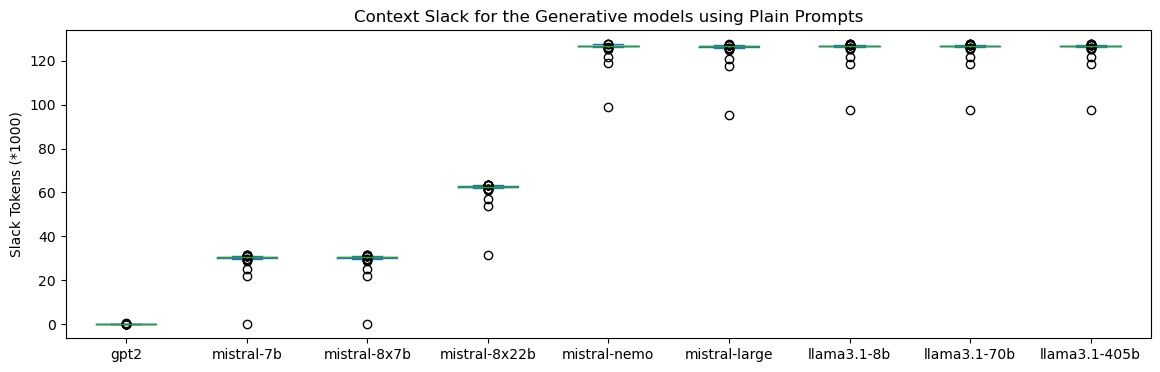

In [8]:
ks = llm[llm['generative']]['key'].dropna().index
df = pd.concat(list( with_prompt[k] *-1 + llm.loc[k, 'context'] for k in ks), axis=1)
for k in ks:
    df.loc[df[k]<0, k] = 0
    df[k] /= 1000

ordre = ['gpt2', 'mistral-7b', 'mistral-8x7b', 'mistral-8x22b', 'mistral-nemo', 'mistral-large', 'llama3.1-8b', 'llama3.1-70b', 'llama3.1-405b']
df[ordre].plot(kind='box', 
        showfliers=True, 
        title='Context Slack for the Generative models using Plain Prompts',
        figsize=(14,4),
        ylabel ='Slack Tokens (*1000)')

<Axes: title={'center': 'Context Slack for the Generative models using Plain Prompts'}, ylabel='Slack Tokens (*1000)'>

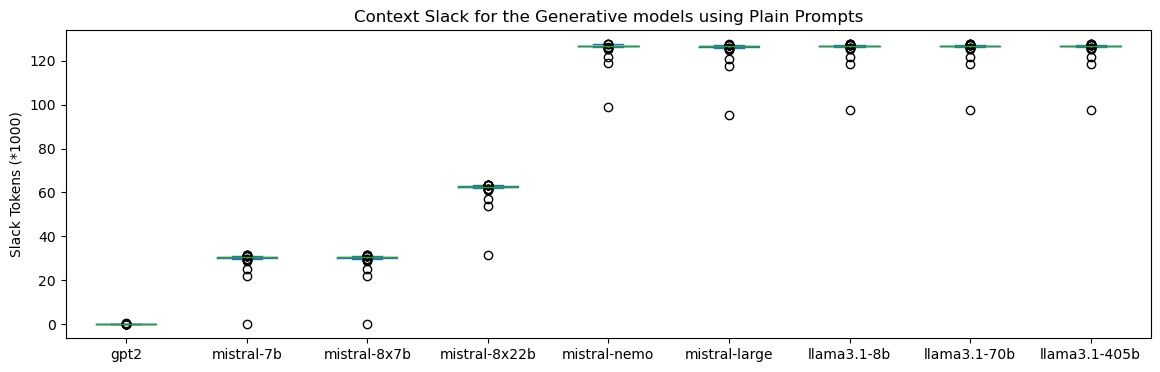

In [9]:
# Using compressed prompts
ks = llm[llm['generative']]['key'].dropna().index
df = pd.concat(list( with_compression[k] *-1 + llm.loc[k, 'context'] for k in ks), axis=1)
for k in ks:
    df.loc[df[k]<0, k] = 0
    df[k] /= 1000

ordre = ['gpt2', 'mistral-7b', 'mistral-8x7b', 'mistral-8x22b', 'mistral-nemo', 'mistral-large', 'llama3.1-8b', 'llama3.1-70b', 'llama3.1-405b']
df[ordre].plot(kind='box', 
        showfliers=True, 
        title='Context Slack for the Generative models using Plain Prompts',
        figsize=(14,4),
        ylabel ='Slack Tokens (*1000)')

In [10]:
# nb tokens vs the case where the tokenizer would have been trained from the data
tok = pd.read_parquet('token_counts/no_prompt.parquet')
tok

text  \
split project file_id                                                      
train pardons 299.txt  kaerle etc doen te wetene allen iegewoirdich e...   
              228.txt  remissie voer\ndiericken gheerits\nkaerle etc....   
              118.txt  philips etc. allen etc. saluit alsoe als tonse...   
              126.txt  philips byder gratien goidts coninck van casti...   
              373.txt  remissie van dootslage\nphilips byder gracien ...   
...                                                                  ...   
valid pardons 012.txt  maximilian par la grace de dieu esleu empereur...   
              099.txt  remissie\nalbert ende isabel clara eugenia etc...   
              315.txt  kaerle etc. doen te wetene allen iegewoirdigen...   
              300.txt  kaerle etc. doen te wetene allen iegewoirdige ...   
              004.txt  kaerle etc. ic doen te wetene allen iegenwoird...   

                       from-scratch  gpt2  gysbertv2  llama3.1-405b  \
split project file_id                                                 
train pardons 299.txt          1099  2438       1560           2157   
              228.txt          1366  3074       1998           2735   
              118.txt           402   756        537            661   
              126.txt          1147  2481       1531           2197   
              373.txt           934  1920       1331           1704   
...                             ...   ...        ...            ...   
valid pardons 012.txt          1131  2234       1903           1967   
              099.txt           426   974        591            853   
              315.txt          1435  3179       2075           2823   
              300.txt          1257  2830       1855           2510   
              004.txt          1873  4071       2669           3592   

                       llama3.1-70b  llama3.1-8b  mistral-7b  mistral-8x22b  \
split project file_id                                                         
train pardons 299.txt          2157         2157        2295           2295   
              228.txt          2735         2735        2910           2910   
              118.txt           661          661         728            728   
              126.txt          2197         2197        2333           2333   
              373.txt          1704         1704        1827           1827   
...                             ...          ...         ...            ...   
valid pardons 012.txt          1967         1967        2117           2117   
              099.txt           853          853         923            923   
              315.txt          2823         2823        3032           3032   
              300.txt          2510         2510        2677           2677   
              004.txt          3592         3592        3898           3898   

                       mistral-8x7b  mistral-large  mistral-nemo  xlm-roberta  
split project file_id                                                          
train pardons 299.txt          2295           2295          2081         1926  
              228.txt          2910           2910          2651         2395  
              118.txt           728            729           644          605  
              126.txt          2333           2334          2081         1932  
              373.txt          1827           1827          1642         1562  
...                             ...            ...           ...          ...  
valid pardons 012.txt          2117           2117          1828         1793  
              099.txt           923            923           841          741  
              315.txt          3032           3032          2719         2489  
              300.txt          2677           2677          2417         2219  
              004.txt          3898           3898          3466         3228  

[419 rows x 13 columns]

<Axes: title={'center': 'Token count ratio vs that of a tokenizer trained from the data'}>

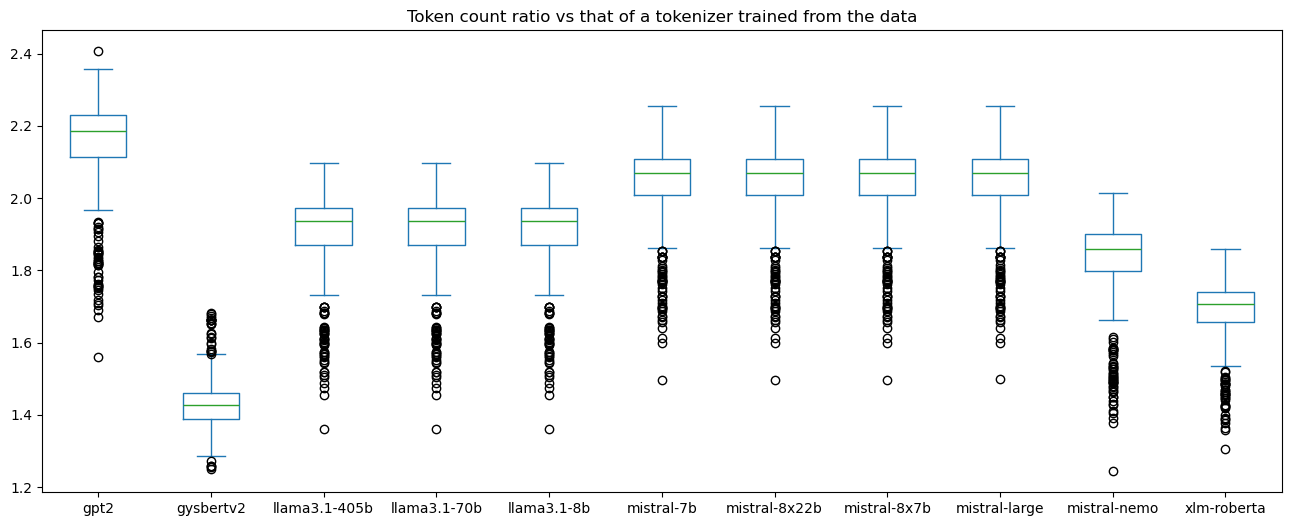

In [11]:
df = pd.DataFrame()
for k in tok.columns[2:]:
    df[k] = tok[k] / tok['from-scratch']
df.plot(kind='box',
        title='Token count ratio vs that of a tokenizer trained from the data',
        figsize=(16,6)
       )

<Axes: title={'center': 'A priori proxy for the zero-shot model efficacy (MMLU)'}, xlabel='MMLU Score'>

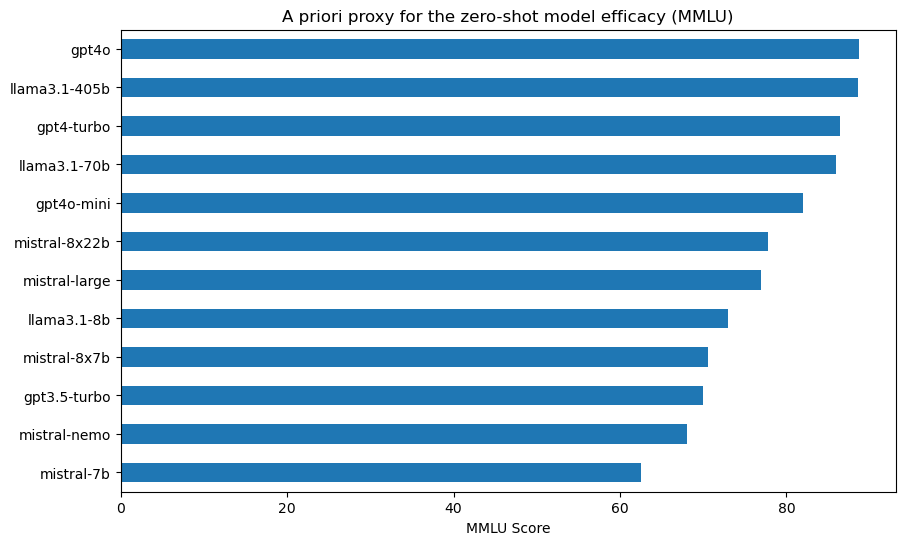

In [12]:
llm.mmlu.dropna().sort_values().plot(
    title='A priori proxy for the zero-shot model efficacy (MMLU)',
    kind='barh', 
    xlabel='MMLU Score', 
    ylabel='', 
    figsize=(10,6)
)

<Axes: title={'center': 'Memory Requirements in GigaBytes of RAM assuming 16 bits representation'}, xlabel='Memory Requirement in GB'>

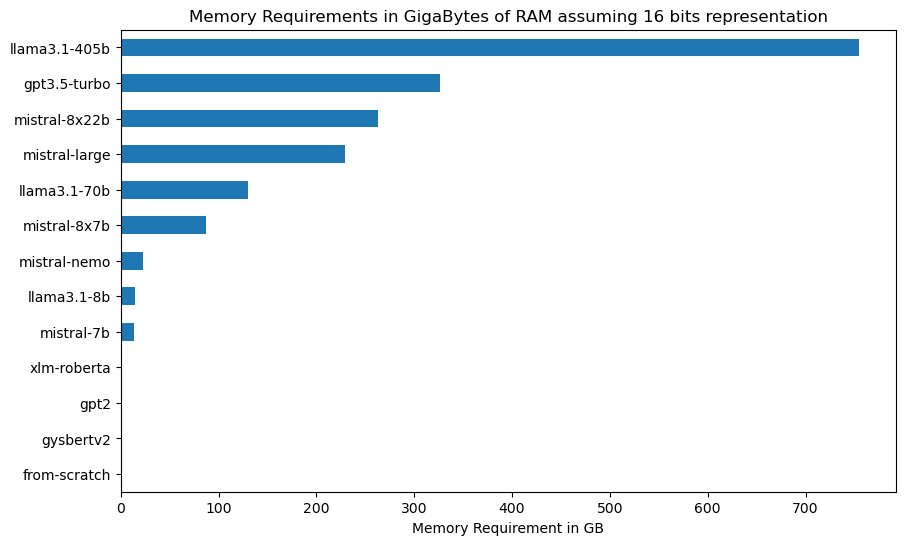

In [13]:
(llm.params.dropna().sort_values() * 2 / 1024**3).plot(
    title ='Memory Requirements in GigaBytes of RAM assuming 16 bits representation',
    kind='barh', 
    ylabel='',
    xlabel='Memory Requirement in GB', 
    figsize=(10,6)
)

In [19]:
(llm.params.dropna().sort_values() * 2 / 1024**3)

id
from-scratch       0.195578
gysbertv2          0.203028
gpt2               0.255182
xlm-roberta        1.041219
mistral-7b        13.504177
llama3.1-8b       14.957041
mistral-nemo      22.724271
mistral-8x7b      86.985528
llama3.1-70b     130.496919
mistral-large    229.105353
mistral-8x22b    262.632966
gpt3.5-turbo     325.962901
llama3.1-405b    754.371285
Name: params, dtype: float64

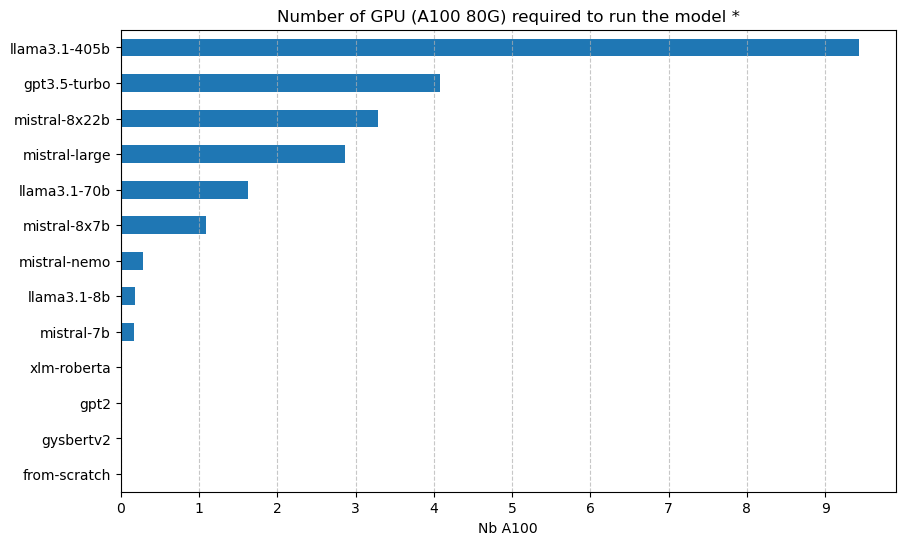

In [15]:
ax = (llm.params.dropna().sort_values() * 2 / 1024**3 / 80).plot(
    title ='Number of GPU (A100 80G) required to run the model *',
    kind='barh', 
    ylabel='',
    xlabel='Nb A100', 
    xticks=range(10),
    figsize=(10,6)
)
ax.grid(axis='x', linestyle='--', alpha=0.7)

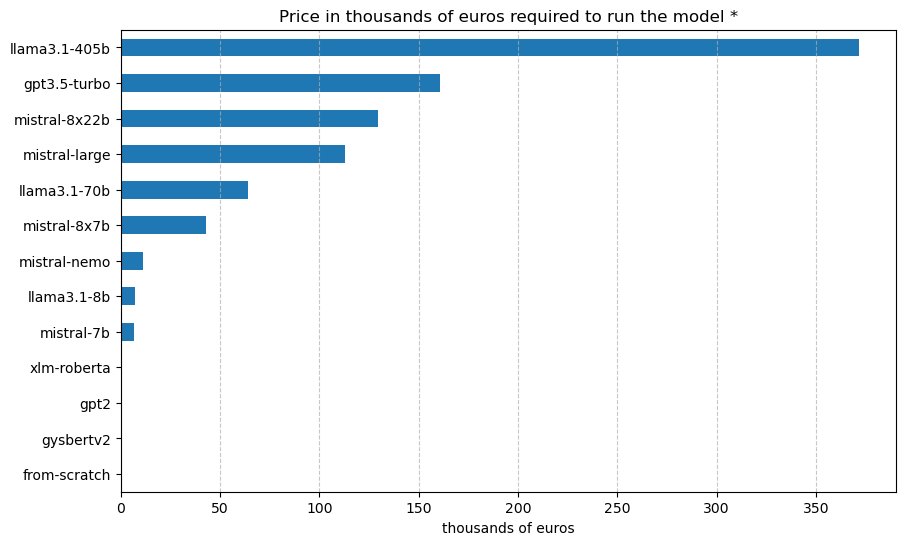

In [17]:
ax = (llm.params.dropna().sort_values() * 2 / 1024**3 / 40 * 19.700).plot(
    title ='Price in thousands of euros required to run the model *',
    kind='barh', 
    ylabel='',
    xlabel='thousands of euros', 
    figsize=(10,6)
)
ax.grid(axis='x', linestyle='--', alpha=0.7)

In [18]:
(llm.params.dropna().sort_values() * 2 / 1024**3 / 40 * 19.700)

id
from-scratch       0.096322
gysbertv2          0.099991
gpt2               0.125677
xlm-roberta        0.512800
mistral-7b         6.650807
llama3.1-8b        7.366342
mistral-nemo      11.191703
mistral-8x7b      42.840373
llama3.1-70b      64.269733
mistral-large    112.834387
mistral-8x22b    129.346736
gpt3.5-turbo     160.536729
llama3.1-405b    371.527858
Name: params, dtype: float64